# **Mean Imputation**
Replacing missing value with the mean of the data.


**Rules for imputation**:

- If the missing value percentage in any variable is high than 5 then we have not to impute the missing value and we can drop that variable.
- If the missing values is not missing complete at random (MCAR) then we should not impute them.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
df = pd.read_csv("data/titanic.csv").drop(columns=["PassengerId", "Ticket"])

In [16]:
df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,NaN,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C85,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,NaN,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,C123,S
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,NaN,S


In [17]:
round((df.isna().sum()/df.shape[0])*100, 0)

Survived     0.0
Pclass       0.0
Name         0.0
Sex          0.0
Age         20.0
SibSp        0.0
Parch        0.0
Fare         0.0
Cabin       77.0
Embarked     0.0
dtype: float64

**the age columns have 20% missing values actually we cant impute it but just for practice purpose we have to impute this.**

**Checking MCAR**

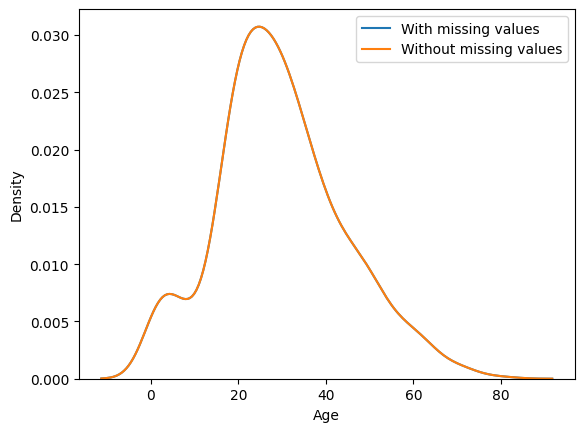

In [18]:
sns.kdeplot(df["Age"], label="With missing values")
sns.kdeplot(df["Age"].dropna(), label="Without missing values")
plt.legend()
plt.show()

**As concluded from the above kde plot that the data is missing complete at random so we can impute it**

In [19]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Survived"])
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [20]:
from sklearn.compose import ColumnTransformer

t = ColumnTransformer(transformers=[
    ("imputer", SimpleImputer(strategy="mean"), ["Age"])
], remainder="passthrough")

In [21]:
X_train["Age"].isna().sum()

np.int64(140)

In [22]:
X_train = pd.DataFrame(t.fit_transform(X_train), columns=t.get_feature_names_out())
X_test = pd.DataFrame(t.fit_transform(X_test), columns=t.get_feature_names_out())

In [31]:
X_train

,imputer__Age,remainder__Pclass,remainder__Name,remainder__Sex,remainder__SibSp,remainder__Parch,remainder__Fare,remainder__Cabin,remainder__Embarked
0,45.5,1,"Partner, Mr. Austen",male,0,0,28.5,C124,S
1,23.0,2,"Berriman, Mr. William John",male,0,0,13.0,NaN,S
2,32.0,3,"Tikkanen, Mr. Juho",male,0,0,7.925,NaN,S
3,26.0,3,"Hansen, Mr. Henrik Juul",male,1,0,7.8542,NaN,S
4,6.0,3,"Andersson, Miss. Ebba Iris Alfrida",female,4,2,31.275,NaN,S
...,...,...,...,...,...,...,...,...,...
707,21.0,3,"Salkjelsvik, Miss. Anna Kristine",female,0,0,7.65,NaN,S
708,29.498846,1,"Cairns, Mr. Alexander",male,0,0,31.0,NaN,S
709,41.0,3,"Hansen, Mr. Claus Peter",male,2,0,14.1083,NaN,S
710,14.0,1,"Carter, Miss. Lucile Polk",female,1,2,120.0,B96 B98,S


In [32]:
X_train["imputer__Age"].isna().sum()

np.int64(0)